# 교과서에서 전처리·탐색한 `weather2023.xlsx`를 이용하여  
기온(temp), 풍속(wind), 습도(humi), 전운량(cloud)으로  
합계 일조시간(sunshine)을 예측하는 선형회귀 모델을 만드는 실습이다.

<탐구질문> 오늘의 기온, 풍속,습도, 전운량을 알면 일조시간을 예측할 수 있을까?

STEP 1. 라이브러리 불러오기와 데이터 확인, 데이터 전처리


In [72]:
import pandas as pd
import matplotlib.pyplot as plt

weather = pd.read_excel('../Data/04. weather2023.xlsx', index_col='date')
weather.drop(weather[['rain', 'loc_name','location']], axis=True, inplace=True)
weather.head()



,temp,wind,humi,sunshine,cloud
date,,,,,
2023-01-01,-0.2,2.7,55.0,9.0,1.3
2023-01-02,-4.5,2.5,46.0,9.1,0.0
2023-01-03,-5.0,1.8,49.0,9.1,0.0
2023-01-04,-1.8,1.9,51.0,8.7,1.9
2023-01-05,-1.6,1.6,58.1,4.7,3.6


STEP 2-1. 특성변수 후보와 목표변수의 관계 시각화하기(1)

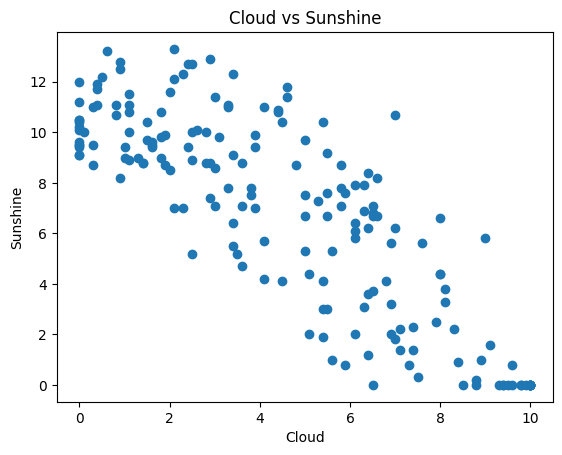

In [73]:
plt.scatter(weather['cloud'], weather['sunshine'])
plt.xlabel('Cloud')
plt.ylabel('Sunshine')
plt.title('Cloud vs Sunshine')
plt.show()

STEP 2-2. 특성변수 후보와 목표변수의 관계 시각화하기(2)


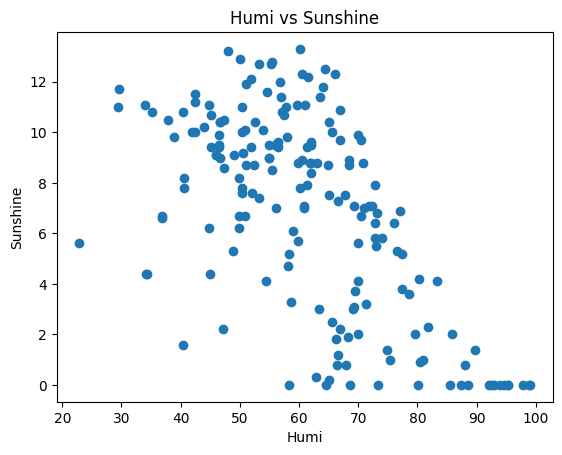

In [74]:
plt.scatter(weather['humi'], weather['sunshine'])
plt.xlabel('Humi')
plt.ylabel('Sunshine')
plt.title('Humi vs Sunshine')
plt.show()

STEP3. 입력 데이터 X와 정답 y 정하기

In [75]:
X = weather[['temp', 'wind', 'cloud', 'humi']]
y = weather['sunshine']
print(X.head())
print(y.head())

            temp  wind  cloud  humi
date                               
2023-01-01  -0.2   2.7    1.3  55.0
2023-01-02  -4.5   2.5    0.0  46.0
2023-01-03  -5.0   1.8    0.0  49.0
2023-01-04  -1.8   1.9    1.9  51.0
2023-01-05  -1.6   1.6    3.6  58.1
date
2023-01-01    9.0
2023-01-02    9.1
2023-01-03    9.1
2023-01-04    8.7
2023-01-05    4.7
Name: sunshine, dtype: float64


STEP4. 훈련데이터와 테스트테이터로 분리하기

In [76]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [77]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42
)
print(f'훈련데이터: {X_train.shape}')
print(f'테스트데이터: {X_test.shape}')

훈련데이터: (144, 4)
테스트데이터: (37, 4)


STEP5. 모델1: 선형회귀 모델 학습하기

In [78]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train);


STEP6. 모델1: 테스트 데이터 예측하기

In [79]:
pred = model.predict(X_test)
result = pd.DataFrame({
  'original_index': y_test.index,
  'artual': y_test.values,
  'predited': pred
})
print(result.head(10))

  original_index  artual   predited
0     2023-01-20     8.7  10.220608
1     2023-02-12     2.0   2.696020
2     2023-06-03    13.3  10.724790
3     2023-03-20    10.0   8.865658
4     2023-05-26    10.7   5.592091
5     2023-01-16     8.8   6.580402
6     2023-01-25     9.4   8.029100
7     2023-03-10     9.6  11.635115
8     2023-04-24     7.8   7.349061
9     2023-04-29     0.8   0.118703


STEP7. 모델1: 성능 평가하기

In [80]:
from sklearn.metrics import mean_absolute_error, r2_score
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
print(f'선형회귀 MAE: {mae}') # 0에 가까울수록 좋음
print(f'선형회귀 R2: {r2}') # 1에 가까울수록 좋음

선형회귀 MAE: 1.4872732719755144
선형회귀 R2: 0.7737787722337529


STEP8. 모델2: 랜덤포레스트 학습, 예측, 성능평가 (STEP5~7 모델명만 바꿔서 학습)

In [81]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42) # 랜덤 포레스트 모델 학습
rf_model.fit(X_train, y_train) # 테스트 데이터 예측
rf_pred = rf_model.predict(X_test) # 랜덤 포레스트 성능 평가

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)
print(f'랜덤 포레스트 MAE: {rf_mae}') 
print(f'랜덤 포레스트 R2: {rf_r2}') 

랜덤 포레스트 MAE: 1.39754054054054
랜덤 포레스트 R2: 0.7906717868788553


STEP9. 모델1과 모델2: 성능비교 

In [82]:
print(f'선형회귀 MAE: {mae}')
print(f'선형회귀 R2: {r2}')
print()
print(f'랜덤 포레스트 MAE: {rf_mae}') 
print(f'랜덤 포레스트 R2: {rf_r2}') 

선형회귀 MAE: 1.4872732719755144
선형회귀 R2: 0.7737787722337529

랜덤 포레스트 MAE: 1.39754054054054
랜덤 포레스트 R2: 0.7906717868788553


STEP10. 성능 평가 결과로 모델 선정, 실제값과 예측값 시각화하기

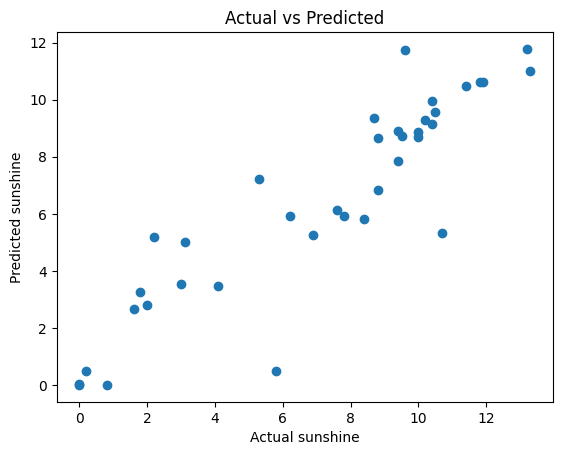

In [84]:
plt.scatter(y_test, rf_pred)
plt.xlabel('Actual sunshine')
plt.ylabel('Predicted sunshine')
plt.title('Actual vs Predicted')
plt.show()

STEP 11. 새로운 날씨 데이터 예측하기

 - X값 중 하나 이상을 바꾸어 새로운 날씨의 일조 시간 예측

In [89]:
new_weather = pd.DataFrame({
  'temp':[20.0],
  'wind': [2.5],
  'cloud': [4.0],
  'humi': [60.0]
})

new_pred = model.predict(new_weather)
print(f'예측 일조시간: {new_pred[0]}')

예측 일조시간: 8.46728864137906


<회귀 모델 성능지표 해석>

MAE: 작을수록 좋음 (실제값과 예측값이 평균적으로 얼마나 차이 나는지?)

R²: 1에 가까울수록 좋음 (모델이 실제 데이터의 변화를 얼마나 잘 설명하는지?)

STEP10. 랜덤포레스트 회귀와 비교